# Hyperparameter Tuning with Randomized Search

This tutorial tunes a random-forest regressor with `RandomizedSearchCV`. A deterministic synthetic regression fixture keeps the workflow executable, while a holdout set remains untouched until the final comparison.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split

RANDOM_SEED = 15
OUTPUT_DIR = Path('generated/tuning-015')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features, target = make_regression(
    n_samples=600,
    n_features=12,
    n_informative=7,
    noise=18,
    random_state=RANDOM_SEED,
)
X = pd.DataFrame(features, columns=[f'feature_{index:02d}' for index in range(features.shape[1])])
y = pd.Series(target, name='target')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_SEED
)
print(f'train rows: {len(X_train)}; holdout rows: {len(X_test)}')

train rows: 450; holdout rows: 150


## 1. Define the Search

Randomized search samples a fixed number of parameter combinations. Cross-validation happens only on training rows, which prevents the final holdout from influencing model selection.

In [2]:
parameter_distributions = {
    'n_estimators': [100, 160, 240],
    'max_depth': [None, 6, 12],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [0.6, 0.8, 1.0],
}
cross_validation = KFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1),
    param_distributions=parameter_distributions,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=cross_validation,
    random_state=RANDOM_SEED,
    n_jobs=1,
    return_train_score=True,
)
search.fit(X_train, y_train)
print('best parameters:', search.best_params_)
print(f'best cross-validation RMSE: {-search.best_score_:.2f}')

best parameters: {'n_estimators': 160, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 12}
best cross-validation RMSE: 37.11


## 2. Evaluate Once on the Holdout

The tuned forest is compared with a mean-value baseline. The baseline makes it clear whether tuning produces useful predictive signal rather than only a better-looking score.

In [3]:
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
predictions = search.best_estimator_.predict(X_test)
baseline_predictions = baseline.predict(X_test)
metrics = pd.DataFrame(
    {
        'RMSE': [
            root_mean_squared_error(y_test, predictions),
            root_mean_squared_error(y_test, baseline_predictions),
        ],
        'MAE': [
            mean_absolute_error(y_test, predictions),
            mean_absolute_error(y_test, baseline_predictions),
        ],
    },
    index=['Tuned random forest', 'Mean baseline'],
)
print(metrics.round(2).to_string())
assert metrics.loc['Tuned random forest', 'RMSE'] < metrics.loc['Mean baseline', 'RMSE']

                      RMSE    MAE
Tuned random forest  35.28  27.90
Mean baseline        85.21  66.58


## 3. Inspect Search and Prediction Quality

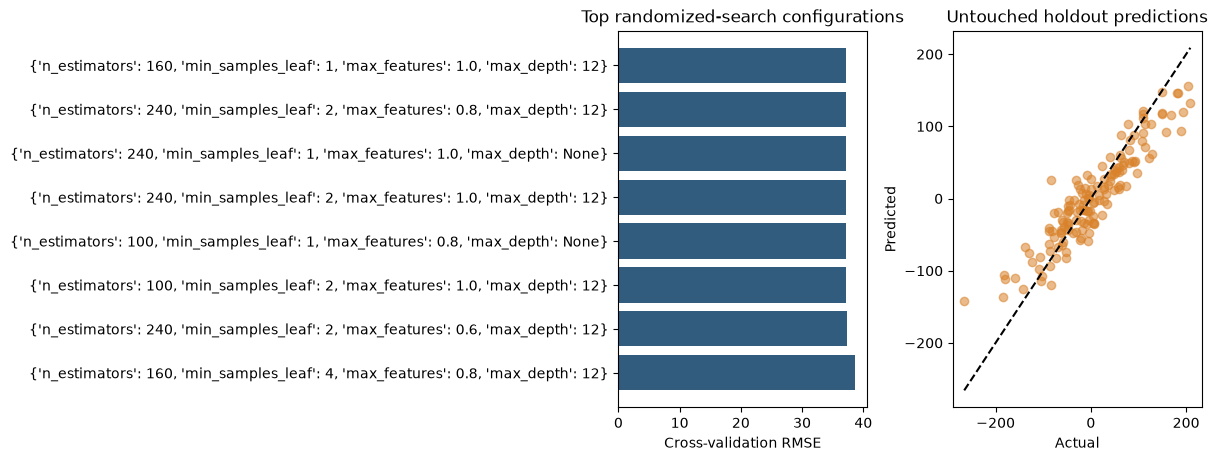

saved: generated\tuning-015\randomized-search-regression.png


In [4]:
search_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(8)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].barh(
    search_results['params'].astype(str).str.replace('RandomForestRegressor', '', regex=False),
    -search_results['mean_test_score'],
    color='#315c7d',
)
axes[0].invert_yaxis()
axes[0].set(title='Top randomized-search configurations', xlabel='Cross-validation RMSE')
axes[1].scatter(y_test, predictions, alpha=0.55, color='#d9822b')
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[1].plot(limits, limits, color='black', linestyle='--')
axes[1].set(title='Untouched holdout predictions', xlabel='Actual', ylabel='Predicted')
figure_path = OUTPUT_DIR / 'randomized-search-regression.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')